# 🧠 SwinMamba + IS-MIM: Real-Time Module-Wise Output Notebook
### Step-by-Step Layer Activation Verification on Real Patient MRI Datasets

This notebook loads a **real patient MRI scan** from `Dataset/Glioma/<subject_id>`, passes the 4-modality 3D volume (`T1n`, `T1c`, `T2w`, `FLAIR`) through the fine-tuned **SwinMamba Dual-Task Neural Network** (`checkpoints/finetune/finetune_best.pt`), and delivers **real-time tensor shapes, value statistics (min, mean, max, std), and feature activations** for every module layer in the architecture.

---
### Directory & Environment Setup

In [1]:
import os
import sys
import glob
import time
import numpy as np
import nibabel as nib
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Ensure workspace is in path
sys.path.insert(0, "C:/Glioma")

from src.models import SwinMambaDual
from src.data.transforms import (
    normalize_intensity,
    crop_or_pad_3d,
    convert_brats_labels,
    extract_glioma_grade,
)
from src.utils.metrics import evaluate_segmentation_case
from src.utils.postprocessing import postprocess_predictions

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✓ PyTorch Execution Device: {device}")


✓ PyTorch Execution Device: cuda


---
## Stage 0 │ Real Patient MRI Dataset Loader
Specify any patient subject ID from `Dataset/Glioma` (e.g., `BraTS-GLI-00000-000`, `BraTS-GLI-00002-000`). If omitted, automatically selects the first available patient.

✓ Loaded Patient: BraTS-GLI-00000-000
  Input Tensor Shape : (1, 4, 96, 96, 96)  [B=1, C=4, D=96, H=96, W=96]
  Voxel Value Range  : min=-3.356 | mean=-0.001 | max=+6.101 | std=0.890
  Ground Truth Grade : HGG (High-Level Glioma)


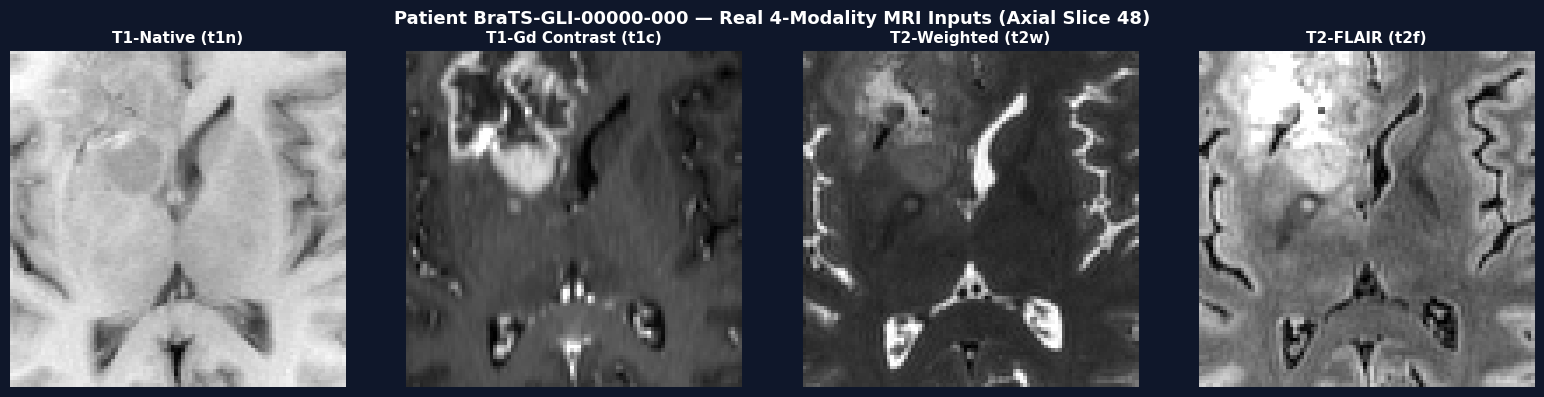

In [2]:
DATA_DIR = "C:/Glioma/Dataset/Glioma"
SUBJECT_ID = "BraTS-GLI-00000-000"  # Change to any patient ID in Dataset/Glioma

all_subjects = sorted([d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)) and d.startswith("BraTS")])
if SUBJECT_ID not in all_subjects:
    SUBJECT_ID = all_subjects[0]

subj_folder = os.path.join(DATA_DIR, SUBJECT_ID)
mod_keys = ["t1n", "t1c", "t2w", "t2f"]
vols = []

for mk in mod_keys:
    matches = glob.glob(os.path.join(subj_folder, f"*{mk}*.nii*"))
    if not matches:
        matches = [f for f in glob.glob(os.path.join(subj_folder, "*.nii*")) if "seg" not in f]
    vols.append(nib.load(matches[0]).get_fdata(dtype=np.float32))

vol_4ch = np.stack(vols, axis=0)
tensor_4ch = torch.from_numpy(vol_4ch)
norm_tensor = normalize_intensity(tensor_4ch)
input_tensor = crop_or_pad_3d(norm_tensor, target_shape=(96, 96, 96)).unsqueeze(0).to(device)

# Load Ground Truth Seg & Grade if available
seg_matches = glob.glob(os.path.join(subj_folder, "*seg*.nii*"))
gt_tensor = None
gt_grade = None
if seg_matches:
    raw_seg = nib.load(seg_matches[0]).get_fdata(dtype=np.float32)
    gt_3ch = convert_brats_labels(torch.from_numpy(raw_seg).unsqueeze(0))
    gt_tensor = crop_or_pad_3d(gt_3ch, target_shape=(96, 96, 96))
    gt_grade = extract_glioma_grade(gt_tensor)

print(f"✓ Loaded Patient: {SUBJECT_ID}")
print(f"  Input Tensor Shape : {tuple(input_tensor.shape)}  [B=1, C=4, D=96, H=96, W=96]")
print(f"  Voxel Value Range  : min={input_tensor.min():+.3f} | mean={input_tensor.mean():+.3f} | max={input_tensor.max():+.3f} | std={input_tensor.std():.3f}")
if gt_grade is not None:
    print(f"  Ground Truth Grade : {'HGG (High-Level Glioma)' if gt_grade==1 else 'LGG (Low-Level Glioma)'}")

# Visualise 4 Modalities
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
fig.patch.set_facecolor("#0f172a")
mod_names = ["T1-Native (t1n)", "T1-Gd Contrast (t1c)", "T2-Weighted (t2w)", "T2-FLAIR (t2f)"]
for idx in range(4):
    slice_2d = np.rot90(input_tensor[0, idx, :, :, 48].cpu().numpy())
    axes[idx].imshow(slice_2d, cmap="gray")
    axes[idx].set_title(mod_names[idx], color="white", fontsize=11, fontweight="bold")
    axes[idx].axis("off")
fig.suptitle(f"Patient {SUBJECT_ID} — Real 4-Modality MRI Inputs (Axial Slice 48)", color="white", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


---
## Load Fine-Tuned SwinMamba Weights
Loads trained weights from `checkpoints/finetune/finetune_best.pt`.

In [3]:
CKPT_PATH = "C:/Glioma/checkpoints/finetune/finetune_best.pt"

model = SwinMambaDual(
    in_chans=4, seg_out_chans=3, num_classes=2,
    feat_size=(48, 96, 192, 384), hidden_size=768, mode="finetune"
).to(device)

if os.path.exists(CKPT_PATH):
    ckpt = torch.load(CKPT_PATH, map_location=device, weights_only=False)
    state_dict = ckpt["model_state_dict"] if "model_state_dict" in ckpt else ckpt
    model.load_state_dict(state_dict)
    print(f"✓ Fine-Tuned Weights Loaded from: {CKPT_PATH}")
    print(f"✓ Model Best Epoch: {ckpt.get('epoch', 'N/A')}  |  Val Mean Dice: {ckpt.get('metrics', {}).get('mean_dice', 0):.4f}")
else:
    print("⚠ Checkpoint not found. Running with initialized weights.")

model.eval()

def log(name: str, t: torch.Tensor, note: str = ""):
    f = t.detach().float()
    print(f"{name:<42}  {str(tuple(t.shape)):<24}  min={f.min():+.3f}  u={f.mean():+.3f}  max={f.max():+.3f}  std={f.std():.3f}  <- {note}")


✓ Fine-Tuned Weights Loaded from: C:/Glioma/checkpoints/finetune/finetune_best.pt
✓ Model Best Epoch: 3  |  Val Mean Dice: 0.8603


---
## Stage 1 │ 3D Convolutional Stem
Initial stem projection layer halving spatial resolution ($96^3 	o 48^3$) and expanding channel capacity ($4 	o 48$).

Stem Conv Output                            (1, 48, 48, 48, 48)       min=-0.123  u=+0.344  max=+12.618  std=0.663  <- Halves resolution 96³→48³, expands 4→48 channels


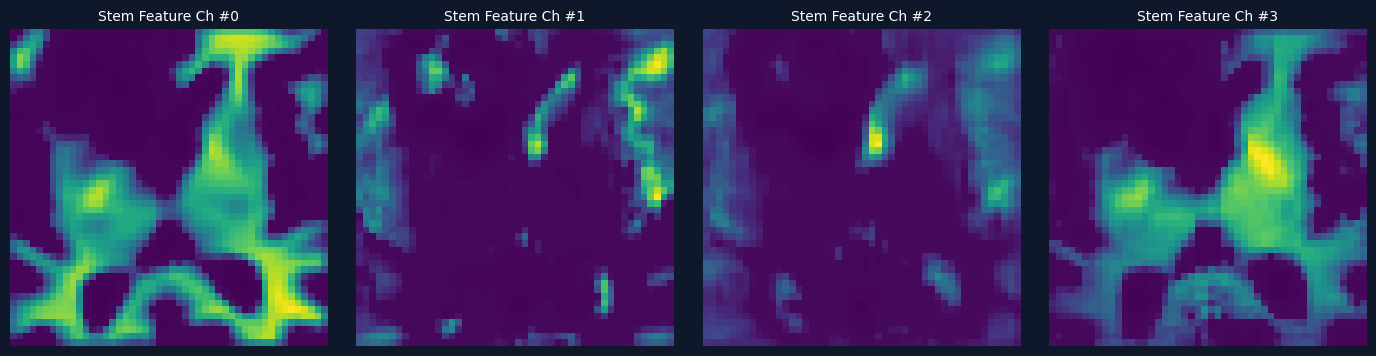

In [4]:
with torch.no_grad():
    x_stem = model.encoder.downsample_layers[0](input_tensor)
    log("Stem Conv Output", x_stem, "Halves resolution 96³→48³, expands 4→48 channels")

# Feature activations visualization
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
fig.patch.set_facecolor("#0f172a")
for i in range(4):
    axes[i].imshow(np.rot90(x_stem[0, i, :, :, 24].cpu().numpy()), cmap="viridis")
    axes[i].set_title(f"Stem Feature Ch #{i}", color="white", fontsize=10)
    axes[i].axis("off")
plt.tight_layout()
plt.show()


---
## Stage 2 │ Swin Transformer Stages (Stages 0 & 1)
Applies local windowed 3D self-attention (W-MSA and SW-MSA).

In [5]:
with torch.no_grad():
    # Stage 0
    x_s0 = x_stem.permute(0, 2, 3, 4, 1)
    for blk_idx, swin_blk in enumerate(model.encoder.swin_stages[0]):
        x_s0 = swin_blk(x_s0)
        log(f"  Swin Stage-0 Block {blk_idx}", x_s0, "3D window self-attention")
    x_s0 = x_s0.permute(0, 4, 1, 2, 3).contiguous()
    x_s0 = model.encoder.mlps[0](model.encoder.norms[0](x_s0))
    log("Stage-0 Output", x_s0, "Stage-0 Skip Feature S0")

    # Stage 1
    x_pm01 = model.encoder.downsample_layers[1](x_s0)
    x_s1 = x_pm01.permute(0, 2, 3, 4, 1)
    for blk_idx, swin_blk in enumerate(model.encoder.swin_stages[1]):
        x_s1 = swin_blk(x_s1)
        log(f"  Swin Stage-1 Block {blk_idx}", x_s1, "3D window self-attention")
    x_s1 = x_s1.permute(0, 4, 1, 2, 3).contiguous()
    x_s1 = model.encoder.mlps[1](model.encoder.norms[1](x_s1))
    log("Stage-1 Output", x_s1, "Stage-1 Skip Feature S1")


  Swin Stage-0 Block 0                      (1, 48, 48, 48, 48)       min=-3.223  u=+0.343  max=+14.960  std=1.054  <- 3D window self-attention
  Swin Stage-0 Block 1                      (1, 48, 48, 48, 48)       min=-4.708  u=+0.518  max=+14.119  std=1.402  <- 3D window self-attention
Stage-0 Output                              (1, 48, 48, 48, 48)       min=-8.663  u=+0.009  max=+10.263  std=0.811  <- Stage-0 Skip Feature S0
  Swin Stage-1 Block 0                      (1, 24, 24, 24, 96)       min=-13.596  u=-0.483  max=+16.115  std=3.089  <- 3D window self-attention
  Swin Stage-1 Block 1                      (1, 24, 24, 24, 96)       min=-13.512  u=-0.559  max=+15.222  std=2.884  <- 3D window self-attention
Stage-1 Output                              (1, 96, 24, 24, 24)       min=-3.399  u=+0.135  max=+2.276  std=0.432  <- Stage-1 Skip Feature S1


---
## Stage 3 │ 3D Tri-Directional Mamba State-Space Encoder (Stages 2 & 3)
Group Spatial Convolution (GSC) + 3D tri-directional Mamba state-space scanning along Axial, Sagittal, and Coronal directions.

In [6]:
with torch.no_grad():
    # Stage 2
    x_pm12 = model.encoder.downsample_layers[2](x_s1)
    x_gsc2 = model.encoder.conv_stages[2](x_pm12)
    log("Stage-2 GSC Conv", x_gsc2, "Group Spatial Convolution enhancement")
    x_m2 = x_gsc2
    for m_idx, mamba_blk in enumerate(model.encoder.mamba_stages[2]):
        x_m2 = mamba_blk(x_m2)
        log(f"  Mamba Stage-2 Layer {m_idx}", x_m2, "Axial + Sagittal + Coronal SSM scan")
    x_s2 = model.encoder.mlps[2](model.encoder.norms[2](x_m2))
    log("Stage-2 Output", x_s2, "Stage-2 Skip Feature S2")

    # Stage 3
    x_pm23 = model.encoder.downsample_layers[3](x_s2)
    x_gsc3 = model.encoder.conv_stages[3](x_pm23)
    log("Stage-3 GSC Conv", x_gsc3, "GSC enhancement before bottleneck SSM")
    x_m3 = x_gsc3
    for m_idx, mamba_blk in enumerate(model.encoder.mamba_stages[3]):
        x_m3 = mamba_blk(x_m3)
        log(f"  Mamba Stage-3 Layer {m_idx}", x_m3, "Deep state-space sequence modeling")
    x_s3 = model.encoder.mlps[3](model.encoder.norms[3](x_m3))
    log("Stage-3 Output", x_s3, "Stage-3 Deep Bottleneck Representation S3")


Stage-2 GSC Conv                            (1, 192, 12, 12, 12)      min=-4.968  u=+0.159  max=+9.467  std=2.144  <- Group Spatial Convolution enhancement
  Mamba Stage-2 Layer 0                     (1, 192, 12, 12, 12)      min=-14.145  u=+0.110  max=+30.664  std=3.428  <- Axial + Sagittal + Coronal SSM scan
  Mamba Stage-2 Layer 1                     (1, 192, 12, 12, 12)      min=-14.146  u=+0.124  max=+32.422  std=3.607  <- Axial + Sagittal + Coronal SSM scan
Stage-2 Output                              (1, 192, 12, 12, 12)      min=-2.540  u=-0.318  max=+3.355  std=0.722  <- Stage-2 Skip Feature S2
Stage-3 GSC Conv                            (1, 384, 6, 6, 6)         min=-5.391  u=+0.694  max=+7.653  std=1.895  <- GSC enhancement before bottleneck SSM
  Mamba Stage-3 Layer 0                     (1, 384, 6, 6, 6)         min=-15.479  u=+0.338  max=+18.374  std=2.711  <- Deep state-space sequence modeling
  Mamba Stage-3 Layer 1                     (1, 384, 6, 6, 6)         min=-17.6

---
## Stage 4 │ UNETR Skip Connection Encoders & Bottleneck Expansion

In [7]:
with torch.no_grad():
    skip_stem  = model.enc_stem(input_tensor)
    skip_0     = model.enc_stage0(x_s0)
    skip_1     = model.enc_stage1(x_s1)
    skip_2     = model.enc_stage2(x_s2)
    bottleneck = model.enc_bottleneck(x_s3)

    log("skip_stem",  skip_stem,  "Raw Input Skip Feature")
    log("skip_0",     skip_0,     "Stage-0 Swin Skip Feature")
    log("skip_1",     skip_1,     "Stage-1 Swin Skip Feature")
    log("skip_2",     skip_2,     "Stage-2 Mamba Skip Feature")
    log("bottleneck", bottleneck, "Expanded Bottleneck Feature (384→768)")


skip_stem                                   (1, 48, 96, 96, 96)       min=-0.173  u=+0.379  max=+14.794  std=0.711  <- Raw Input Skip Feature
skip_0                                      (1, 48, 48, 48, 48)       min=-0.152  u=+0.491  max=+13.754  std=0.888  <- Stage-0 Swin Skip Feature
skip_1                                      (1, 96, 24, 24, 24)       min=-0.085  u=+0.454  max=+7.705  std=0.684  <- Stage-1 Swin Skip Feature
skip_2                                      (1, 192, 12, 12, 12)      min=-0.063  u=+0.330  max=+6.256  std=0.651  <- Stage-2 Mamba Skip Feature
bottleneck                                  (1, 768, 6, 6, 6)         min=-0.061  u=+0.173  max=+4.191  std=0.447  <- Expanded Bottleneck Feature (384→768)


---
## Stage 5 │ UNETR Progressive Decoder (EV2 Skip Fusion)

In [8]:
with torch.no_grad():
    d4 = model.decoder4(bottleneck, skip_2)
    log("dec4 (bottleneck↑ ⊕ skip_2)", d4, "6³→12³ Upsampling & Skip Fusion")
    d3 = model.decoder3(d4, skip_1)
    log("dec3 (d4↑ ⊕ skip_1)",        d3, "12³→24³ Upsampling & Skip Fusion")
    d2 = model.decoder2(d3, skip_0)
    log("dec2 (d3↑ ⊕ skip_0)",        d2, "24³→48³ Upsampling & Skip Fusion")
    d1 = model.decoder1(d2, skip_stem)
    log("dec1 (d2↑ ⊕ skip_stem)",     d1, "48³→96³ Upsampling & Skip Fusion")
    dec_out = model.decoder_refine(d1)
    log("EV2 Refinement (SE Attn)",   dec_out, "Final Refined Decoder Features")


dec4 (bottleneck↑ ⊕ skip_2)                 (1, 192, 12, 12, 12)      min=-0.138  u=+0.621  max=+15.032  std=0.822  <- 6³→12³ Upsampling & Skip Fusion
dec3 (d4↑ ⊕ skip_1)                         (1, 96, 24, 24, 24)       min=-0.139  u=+1.125  max=+17.320  std=1.403  <- 12³→24³ Upsampling & Skip Fusion
dec2 (d3↑ ⊕ skip_0)                         (1, 48, 48, 48, 48)       min=-0.089  u=+1.552  max=+12.826  std=1.510  <- 24³→48³ Upsampling & Skip Fusion
dec1 (d2↑ ⊕ skip_stem)                      (1, 48, 96, 96, 96)       min=-0.143  u=+1.749  max=+16.169  std=2.199  <- 48³→96³ Upsampling & Skip Fusion
EV2 Refinement (SE Attn)                    (1, 48, 96, 96, 96)       min=-0.083  u=+1.524  max=+20.018  std=1.791  <- Final Refined Decoder Features


---
## Stage 6 │ Multi-Task Task Output Heads & Real Patient Predictions

6a. seg_logits                              (1, 3, 96, 96, 96)        min=-9.884  u=-5.574  max=+7.923  std=1.982  <- Raw Voxels Logits (TC | WT | ET)
    seg_probs                               (1, 3, 96, 96, 96)        min=+0.000  u=+0.037  max=+1.000  std=0.160  <- Sigmoid Probabilities

  [REAL PATIENT SEGMENTATION PERFORMANCE]
    • Mean Dice        : 0.8500
    • Whole Tumor (WT) : 0.9089
    • Tumor Core (TC)  : 0.7870
    • Enhancing (ET)   : 0.8541
    • HD95 (mm)        : 2.08 mm

6b. clf_logits                             (1, 2)                    min=-1.335  u=+0.555  max=+2.445  std=2.673  <- Raw Class Scores [0=LGG, 1=HGG]
    clf_probs                               (1, 2)                    min=+0.022  u=+0.500  max=+0.978  std=0.676  <- LGG=0.0223 | HGG=0.9777

  [REAL PATIENT GRADE CLASSIFICATION]
    • Predicted Grade  : HGG (High-Level Glioma)
    • Ground Truth     : HGG (High-Level Glioma)  (✅ Correct Match)


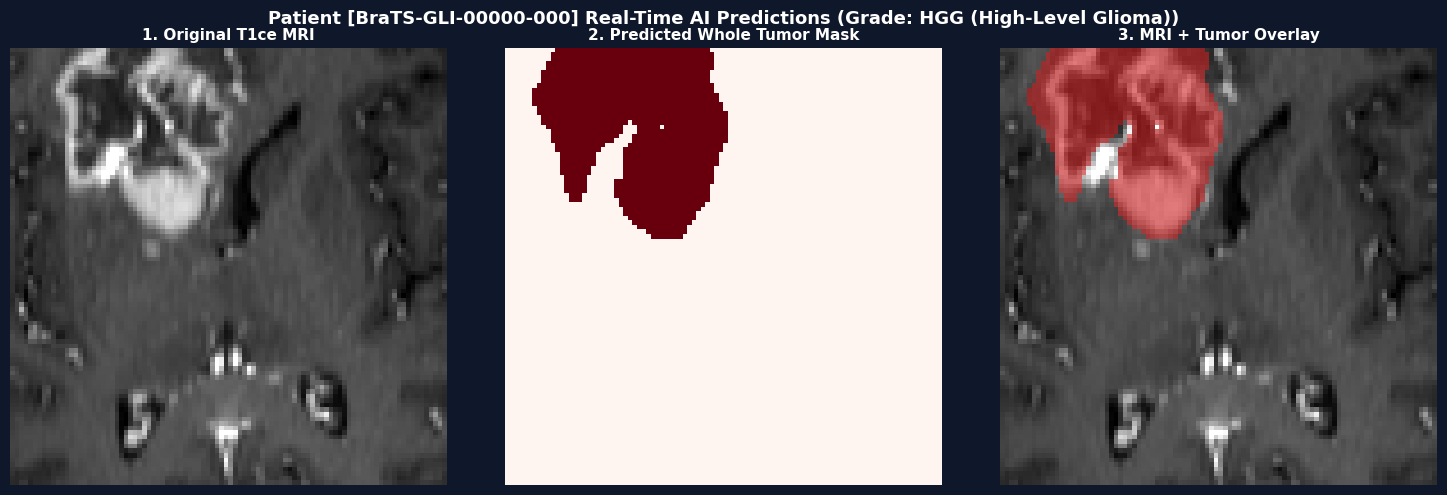

In [9]:
with torch.no_grad():
    # 6a. Segmentation Head
    seg_logits = model.seg_head(dec_out)
    seg_probs  = torch.sigmoid(seg_logits)
    log("6a. seg_logits", seg_logits, "Raw Voxels Logits (TC | WT | ET)")
    log("    seg_probs",  seg_probs,  "Sigmoid Probabilities")

    seg_raw = seg_logits[0].float().cpu().numpy()
    seg_bin = postprocess_predictions(seg_raw)

    if gt_tensor is not None:
        metrics = evaluate_segmentation_case(seg_bin, gt_tensor.numpy())
        print("\n  [REAL PATIENT SEGMENTATION PERFORMANCE]")
        print(f"    • Mean Dice        : {metrics['mean_dice']:.4f}")
        print(f"    • Whole Tumor (WT) : {metrics['dice_wt']:.4f}")
        print(f"    • Tumor Core (TC)  : {metrics['dice_tc']:.4f}")
        print(f"    • Enhancing (ET)   : {metrics['dice_et']:.4f}")
        print(f"    • HD95 (mm)        : {metrics['mean_hd95']:.2f} mm")

    # 6b. Classification Head
    clf_logits = model.clf_head(bottleneck)
    clf_probs  = F.softmax(clf_logits, dim=-1)
    pred_grade = torch.argmax(clf_logits[0]).item()

    log("\n6b. clf_logits", clf_logits, "Raw Class Scores [0=LGG, 1=HGG]")
    log("    clf_probs",  clf_probs,  f"LGG={clf_probs[0,0]:.4f} | HGG={clf_probs[0,1]:.4f}")

    grade_names = ["LGG (Low-Level Glioma)", "HGG (High-Level Glioma)"]
    print(f"\n  [REAL PATIENT GRADE CLASSIFICATION]")
    print(f"    • Predicted Grade  : {grade_names[pred_grade]}")
    if gt_grade is not None:
        print(f"    • Ground Truth     : {grade_names[gt_grade]}  ({'✅ Correct Match' if pred_grade==gt_grade else '❌ Mismatch'})")

# 4-Panel Visualization
mri_2d = input_tensor[0, 1, :, :, 48].cpu().numpy()
mri_norm = (mri_2d - mri_2d.min()) / (mri_2d.max() - mri_2d.min() + 1e-7)
rgb = np.repeat(np.rot90(mri_norm)[:, :, np.newaxis], 3, axis=2)
wt_pred = np.rot90(seg_bin[1, :, :, 48]) > 0.5
overlay = rgb.copy()
overlay[wt_pred] = 0.5 * overlay[wt_pred] + 0.5 * np.array([0.9, 0.1, 0.1])

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor("#0f172a")
axes[0].imshow(np.rot90(mri_norm), cmap="gray")
axes[0].set_title("1. Original T1ce MRI", color="white", fontsize=11, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(wt_pred, cmap="Reds")
axes[1].set_title("2. Predicted Whole Tumor Mask", color="white", fontsize=11, fontweight="bold")
axes[1].axis("off")

axes[2].imshow(overlay)
axes[2].set_title("3. MRI + Tumor Overlay", color="white", fontsize=11, fontweight="bold")
axes[2].axis("off")

fig.suptitle(f"Patient [{SUBJECT_ID}] Real-Time AI Predictions (Grade: {grade_names[pred_grade]})", color="white", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
